# FleetLogix — Proyecto Integrador, Avance 2
## Análisis y optimización SQL

**Motor:** PostgreSQL 18 · **Base de datos:** `fleetlogix` · **Volumen:** 505.650 registros en seis tablas.

**Consultas seleccionadas conforme a la consigna:** **1, 2, 3, 4, 5, 6, 9 y 11**. Se preservan las consultas 7 y 8 únicamente como análisis complementarios históricos.

**Objetivo:** resolver preguntas operativas mediante SQL, analizar planes con `EXPLAIN (ANALYZE, BUFFERS)`, diseñar índices y evaluar sus límites con evidencia observada.

**Archivos adjuntos al proyecto:** `02_queries_analysis.sql` y `03_optimization_indexes.sql`. Las consultas se ejecutan en PostgreSQL/pgAdmin; el notebook documenta y visualiza los resultados registrados.

## 1. Modelo de datos y preguntas de negocio

Tablas: `vehicles` (200), `drivers` (400), `routes` (50), `trips` (100.000), `deliveries` (400.000) y `maintenance` (5.000). Relaciones principales: `trips` referencia vehículos, conductores y rutas; `deliveries` referencia viajes; `maintenance` referencia vehículos.

| Consulta oficial | Pregunta de negocio | Técnica principal |
|---|---|---|
| 1 | ¿Cómo se compone la flota? | `GROUP BY` |
| 2 | ¿Qué licencias requieren renovación? | Filtro temporal |
| 3 | ¿Cuántos viajes hay por estado? | `COUNT`, `GROUP BY` |
| 4 | ¿Dónde se concentran las entregas recientes? | `JOIN`, agregación |
| 5 | ¿Cómo se distribuyen los viajes por conductor activo? | `LEFT JOIN`, `CASE` |
| 6 | ¿Cuál es la productividad por conductor? | `COUNT DISTINCT`, `HAVING` |
| 9 | ¿Cuál es el costo de mantenimiento por kilómetro? | CTE y agregación múltiple |
| 11 | ¿Cómo evolucionan los viajes por mes? | CTE, `LAG`, `LEAD`, promedio móvil |

**Alcance temporal:** los filtros con `CURRENT_DATE` dependen de la fecha de ejecución; las consultas no tienen por qué devolver los mismos resultados en fechas distintas.

## 2. Consultas SQL oficiales seleccionadas

El código se incluye íntegramente a continuación y también en `02_queries_analysis.sql`. Cada consulta debe ejecutarse por separado en pgAdmin.

### Query 1: Contar vehículos por tipo

```sql
-- Query 1: Contar vehículos por tipo
-- Problema de negocio: Conocer la composición de la flota
SELECT 
    vehicle_type,
    COUNT(*) as cantidad
FROM vehicles
GROUP BY vehicle_type
ORDER BY cantidad DESC;
```

### Query 2: Listar conductores con licencia próxima a vencer

```sql
-- Query 2: Listar conductores con licencia próxima a vencer
-- Problema de negocio: Prevenir problemas legales por licencias vencidas
SELECT 
    first_name,
    last_name,
    license_number,
    license_expiry
FROM drivers
WHERE license_expiry < CURRENT_DATE + INTERVAL '30 days'
ORDER BY license_expiry;
```

### Query 3: Total de viajes por estado

```sql
-- Query 3: Total de viajes por estado
-- Problema de negocio: Monitorear operaciones en curso
SELECT 
    status,
    COUNT(*) as total_viajes
FROM trips
GROUP BY status;
```

### Query 4: Total de entregas por ciudad destino en los últimos 2 meses

```sql
-- Query 4: Total de entregas por ciudad destino en los últimos 2 meses
-- Problema de negocio: Identificar demanda por ciudad para planificación de recursos
SELECT 
    r.destination_city,
    COUNT(DISTINCT t.trip_id) as total_viajes,
    COUNT(d.delivery_id) as total_entregas,
    SUM(d.package_weight_kg) as peso_total_kg
FROM routes r
INNER JOIN trips t ON r.route_id = t.route_id
INNER JOIN deliveries d ON t.trip_id = d.trip_id
WHERE t.departure_datetime >= CURRENT_DATE - INTERVAL '60 days'
GROUP BY r.destination_city
ORDER BY total_entregas DESC;
```

### Query 5: Conductores activos con cantidad de viajes completados

```sql
-- Query 5: Conductores activos con cantidad de viajes completados
-- Problema de negocio: Evaluar carga de trabajo por conductor
SELECT 
    d.driver_id,
    d.first_name || ' ' || d.last_name as nombre_completo,
    d.license_expiry,
    COUNT(t.trip_id) as viajes_totales,
    SUM(CASE WHEN t.status = 'completed' THEN 1 ELSE 0 END) as viajes_completados
FROM drivers d
LEFT JOIN trips t ON d.driver_id = t.driver_id
WHERE d.status = 'active'
GROUP BY d.driver_id, d.first_name, d.last_name, d.license_expiry
HAVING COUNT(t.trip_id) > 0
ORDER BY viajes_completados DESC;
```

### Query 6: Promedio de entregas por conductor en los últimos 6 meses

```sql
-- Query 6: Promedio de entregas por conductor en los últimos 6 meses
-- Problema de negocio: Medir productividad individual de conductores
SELECT 
    dr.driver_id,
    dr.first_name || ' ' || dr.last_name as conductor,
    COUNT(DISTINCT t.trip_id) as total_viajes,
    COUNT(d.delivery_id) as total_entregas,
    ROUND(COUNT(d.delivery_id)::NUMERIC / NULLIF(COUNT(DISTINCT t.trip_id), 0), 2) as promedio_entregas_por_viaje,
    ROUND(COUNT(d.delivery_id)::NUMERIC / 180, 2) as promedio_entregas_diarias
FROM drivers dr
INNER JOIN trips t ON dr.driver_id = t.driver_id
INNER JOIN deliveries d ON t.trip_id = d.trip_id
WHERE t.departure_datetime >= CURRENT_DATE - INTERVAL '6 months'
    AND t.status = 'completed'
GROUP BY dr.driver_id, dr.first_name, dr.last_name
HAVING COUNT(DISTINCT t.trip_id) >= 10
ORDER BY promedio_entregas_por_viaje DESC;
```

### Query 9: Costo de mantenimiento por kilómetro recorrido

```sql
-- Query 9: Costo de mantenimiento por kilómetro recorrido
-- Problema de negocio: Evaluar costo-beneficio de cada tipo de vehículo
WITH vehicle_metrics AS (
    SELECT 
        v.vehicle_id,
        v.vehicle_type,
        v.license_plate,
        COUNT(DISTINCT t.trip_id) as total_viajes,
        SUM(r.distance_km) as km_totales,
        SUM(m.cost) as costo_mantenimiento_total,
        COUNT(DISTINCT m.maintenance_id) as cantidad_mantenimientos
    FROM vehicles v
    LEFT JOIN trips t ON v.vehicle_id = t.vehicle_id
    LEFT JOIN routes r ON t.route_id = r.route_id
    LEFT JOIN maintenance m ON v.vehicle_id = m.vehicle_id
    WHERE t.status = 'completed'
    GROUP BY v.vehicle_id, v.vehicle_type, v.license_plate
)
SELECT 
    vehicle_type,
    COUNT(vehicle_id) as cantidad_vehiculos,
    SUM(total_viajes) as viajes_totales,
    SUM(km_totales) as kilometros_totales,
    SUM(costo_mantenimiento_total) as costo_total_mantenimiento,
    ROUND(SUM(costo_mantenimiento_total) / NULLIF(SUM(km_totales), 0), 2) as costo_por_km,
    ROUND(AVG(costo_mantenimiento_total / NULLIF(cantidad_mantenimientos, 0)), 2) as costo_promedio_por_mantenimiento
FROM vehicle_metrics
WHERE km_totales > 0 AND costo_mantenimiento_total > 0
GROUP BY vehicle_type
ORDER BY costo_por_km DESC;
```

### Query 11: Análisis de tendencia de viajes con LAG y LEAD

```sql
-- Query 11: Análisis de tendencia de viajes con LAG y LEAD
-- Problema de negocio: Proyectar necesidades futuras basadas en tendencias
WITH viajes_mensuales AS (
    SELECT 
        DATE_TRUNC('month', departure_datetime) as mes,
        COUNT(*) as total_viajes,
        SUM(total_weight_kg) as peso_total,
        AVG(fuel_consumed_liters) as combustible_promedio
    FROM trips
    WHERE status = 'completed'
    GROUP BY DATE_TRUNC('month', departure_datetime)
)
SELECT 
    TO_CHAR(mes, 'YYYY-MM') as periodo,
    total_viajes,
    LAG(total_viajes, 1) OVER (ORDER BY mes) as viajes_mes_anterior,
    LEAD(total_viajes, 1) OVER (ORDER BY mes) as viajes_mes_siguiente,
    total_viajes - LAG(total_viajes, 1) OVER (ORDER BY mes) as cambio_absoluto,
    ROUND((total_viajes - LAG(total_viajes, 1) OVER (ORDER BY mes))::NUMERIC / 
          NULLIF(LAG(total_viajes, 1) OVER (ORDER BY mes), 0) * 100, 2) as cambio_porcentual,
    ROUND(peso_total / 1000, 2) as toneladas_transportadas,
    ROUND(combustible_promedio, 2) as combustible_promedio_viaje,
    AVG(total_viajes) OVER (ORDER BY mes ROWS BETWEEN 2 PRECEDING AND CURRENT ROW) as promedio_movil_3m
FROM viajes_mensuales
ORDER BY mes DESC
LIMIT 12;
```

## 3. Índices implementados

| Índice | Tabla / columnas | Alcance |
|---|---|---|
| `idx_trips_composite_joins` | `trips(vehicle_id, driver_id, route_id, departure_datetime)` | Parcial: `status = 'completed'` |
| `idx_deliveries_scheduled_datetime` | `deliveries(scheduled_datetime, delivery_status)` | Parcial: `delivery_status = 'delivered'` |
| `idx_maintenance_vehicle_cost` | `maintenance(vehicle_id, cost)` | General |
| `idx_drivers_status_license` | `drivers(status, license_expiry)` | Parcial: `status = 'active'` |
| `idx_routes_metrics` | `routes(route_id, distance_km, destination_city)` | General |

Los cinco índices fueron confirmados como existentes en `pg_indexes`. La mera existencia de un índice **no demuestra** una mejora de rendimiento. En particular, los índices compuestos dependen de su columna inicial y de la selectividad del filtro.

**Contadores observados de `pg_stat_user_indexes`**: entregas 1, conductores 0, mantenimiento 0, rutas 2, viajes 0. Son contadores acumulativos, no pruebas directas de mejora por consulta.

## 4. Medición del rendimiento

**Metodología registrada:** `EXPLAIN (ANALYZE, BUFFERS)`. Los tiempos provienen de ejecuciones individuales compartidas durante el desarrollo, no de un benchmark controlado. Las consultas 9 y 11 solo tienen mediciones con índices existentes; para la 9 también se midió una reescritura de la lógica. Por tanto, **no corresponde atribuir mejoras causales a los índices**.

| Consulta | Antes (ms) | Después (ms) | Variación | Estado de comparación |
|---|---:|---:|---:|---|
| 1 | 0.377 | 0.149 | −60.5 % | Medición individual |
| 2 | 0.212 | 0.197 | −7.1 % | Medición individual |
| 3 | 36.988 | 40.813 | +10.3 % | Medición individual |
| 4 | 143.159 | 88.208 | −38.4 % | Medición individual |
| 5 | 88.767 | 45.308 | −49.0 % | Medición individual |
| 6 | 202.356 | 199.673 | −1.3 % | Medición individual |
| 9 (SQL original) | No registrada | 1511.757 | No calculable | Medición original con índices existentes |
| 9 (SQL corregido) | No registrada | **43.576** | No calculable | Reescritura; no comparación atribuible a índices |
| 11 | No registrada | **75.942** | No calculable | Nueva ejecución; referencia previa 69.664 ms |

Las consultas 7 y 8 tuvieron mediciones adicionales, pero no integran la selección obligatoria de ocho consultas.

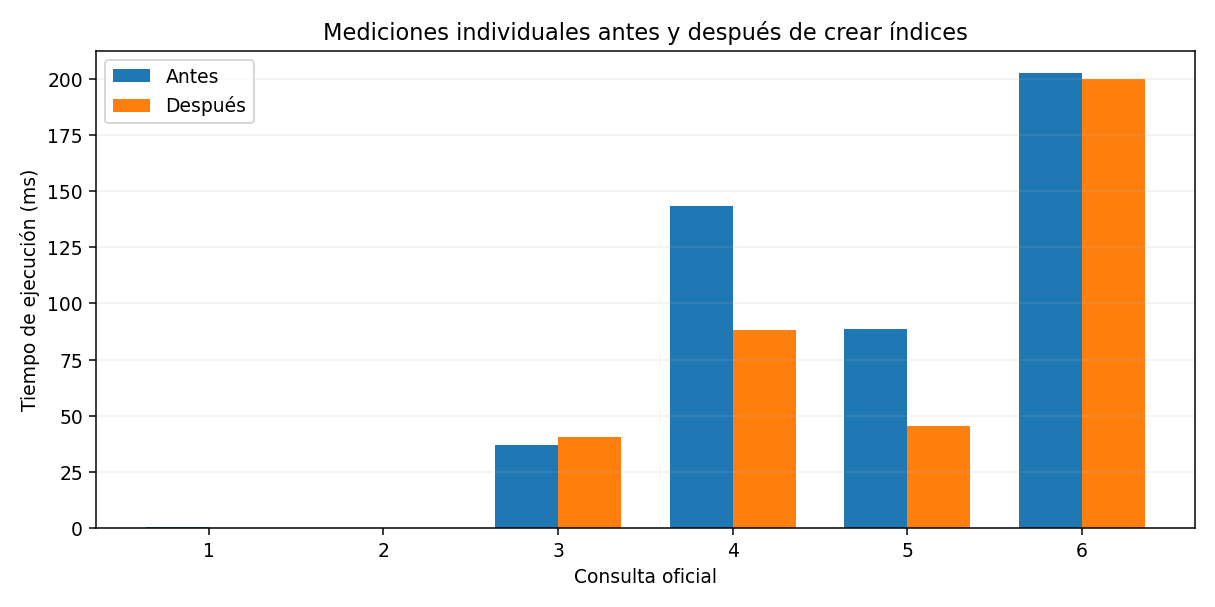

In [1]:
import matplotlib.pyplot as plt

consultas = ['1', '2', '3', '4', '5', '6']
antes = [0.377, 0.212, 36.988, 143.159, 88.767, 202.356]
despues = [0.149, 0.197, 40.813, 88.208, 45.308, 199.673]

fig, ax = plt.subplots(figsize=(9, 4.5))
x = range(len(consultas))
ax.bar([i - 0.18 for i in x], antes, width=0.36, label='Antes')
ax.bar([i + 0.18 for i in x], despues, width=0.36, label='Después')
ax.set_xticks(list(x), consultas)
ax.set_xlabel('Consulta oficial')
ax.set_ylabel('Tiempo de ejecución (ms)')
ax.set_title('Mediciones individuales antes y después de crear índices')
ax.legend()
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()

### Interpretación de las mediciones

Las consultas 1, 2, 4, 5 y 6 muestran tiempos posteriores inferiores en estas mediciones; la 3 muestra un aumento. **No es una prueba de causalidad**: influyen caché, carga, paralelismo, estadísticas y planes. Los resultados de las consultas 1 y 2 son inferiores a 1 ms y diferencias absolutas muy pequeñas deben interpretarse con cautela. La consulta 9 original tardó 1511.757 ms y su reescritura validada por el estudiante tardó 43.576 ms (reducción observada de 97.1 %). **Son consultas de lógica distinta**, por lo que no constituyen una medición antes/después de crear índices. La consulta 11 pasó de 69.664 a 75.942 ms entre dos ejecuciones con índices existentes (+9.0 %); esa variación tampoco mide el efecto de un índice.

## 5. Evidencia de planes de ejecución y análisis técnico

## Análisis del plan de ejecución — Consulta 1

**Consulta:** Vehículos agrupados por tipo.

**Objetivo de negocio:** conocer la composición de la flota de FleetLogix para facilitar la planificación de recursos.

### Operaciones identificadas

- **Seq Scan on vehicles:** PostgreSQL recorre los 200 registros de la tabla de vehículos.
- **HashAggregate:** agrupa los vehículos por `vehicle_type` y calcula la cantidad de cada tipo.
- **Sort:** ordena los resultados de mayor a menor cantidad.
- **Memory Usage:** 32 KB para la operación de agrupación.

### Comparación del rendimiento

| Medición | Tiempo |
|---|---:|
| Antes de crear índices | 0.377 ms |
| Primera medición posterior | 0.149 ms |
| Segunda medición posterior | 0.123 ms |

### Interpretación

El plan no muestra utilización de los cinco índices creados durante el Avance 2.

PostgreSQL realiza un escaneo secuencial porque la tabla `vehicles` contiene solamente 200 registros y la consulta necesita agruparlos todos.

La reducción observada en el tiempo de ejecución no puede atribuirse directamente a los índices nuevos.

**Conclusión:** para tablas pequeñas y consultas sin filtros selectivos, un escaneo secuencial puede resultar más eficiente que utilizar un índice.

## Análisis del plan de ejecución — Consulta 2

**Consulta:** Licencias de conductores próximas a vencer.

**Objetivo de negocio:** identificar conductores con licencias vencidas o próximas a vencer para anticipar renovaciones y evitar riesgos operativos.

### Operaciones identificadas

- **Seq Scan on drivers:** PostgreSQL recorre los 400 registros de conductores.
- **Filter:** comprueba cuáles tienen una licencia con vencimiento anterior a los próximos 30 días.
- **Rows Removed by Filter: 400:** ningún conductor cumple la condición.
- **Sort:** ordena los resultados por `license_expiry`.

### Comparación del rendimiento

| Medición | Tiempo |
|---|---:|
| Antes de crear índices | 0.212 ms |
| Primera medición posterior | 0.197 ms |
| Segunda medición posterior | 0.299 ms |

### Interpretación

PostgreSQL no utilizó el índice parcial `idx_drivers_status_license`.

La consulta filtra únicamente por fecha de vencimiento, mientras que el índice está restringido a conductores cuyo estado es `active`.

Además, al tratarse de una tabla pequeña de 400 registros, el escaneo secuencial tiene un costo bajo.

**Conclusión:** no se observó una mejora atribuible al índice. Para evaluar su utilidad sería necesario probar una consulta que incluya explícitamente la condición `status = 'active'`.

## Análisis del plan de ejecución — Consulta 3

**Consulta:** Viajes agrupados por estado.

**Objetivo de negocio:** conocer cuántos viajes se encuentran en cada estado para monitorear las operaciones logísticas de FleetLogix.

### Operaciones identificadas

- **Seq Scan on trips:** PostgreSQL recorre los 100.000 registros de la tabla `trips`.
- **HashAggregate:** agrupa los resultados por la columna `status`.
- **Memory Usage:** 32 KB utilizados para la agrupación.
- **Buffers: shared hit=1032:** indica que los bloques consultados estaban disponibles en memoria caché.

### Comparación del rendimiento

| Medición | Tiempo |
|---|---:|
| Antes de crear índices | 36.988 ms |
| Primera medición posterior | 40.813 ms |
| Segunda medición posterior | 44.381 ms |

### Interpretación

El plan de ejecución muestra un escaneo secuencial completo de la tabla `trips`, seguido de una operación de agrupación.

PostgreSQL no utilizó ninguno de los cinco índices nuevos. Esto es razonable porque la consulta necesita procesar todos los viajes, sin aplicar filtros selectivos.

Las diferencias de tiempo entre ejecuciones pueden deberse a variaciones normales del entorno.

**Conclusión:** para esta consulta, los índices creados no aportaron una mejora observable en el plan de ejecución.

## Análisis del plan de ejecución — Consulta 4

**Consulta:** Entregas por ciudad de destino.

**Objetivo:** Analizar la cantidad de viajes, entregas y peso transportado por ciudad durante los últimos 60 días.

### Operaciones identificadas

- **Parallel Seq Scan on deliveries:** PostgreSQL realiza una lectura secuencial paralela de la tabla de entregas.
- **Parallel Bitmap Heap Scan on trips:** recupera los viajes que cumplen la condición de fecha.
- **Bitmap Index Scan on idx_trips_departure:** utiliza un índice existente sobre `departure_datetime`.
- **Seq Scan on routes:** realiza una lectura secuencial de la tabla de rutas, que contiene 50 registros.
- **Hash Join y Parallel Hash Join:** relacionan los registros de rutas, viajes y entregas.
- **GroupAggregate y Sort:** agrupan los resultados por ciudad y los ordenan por cantidad de entregas.

### Resultados de rendimiento

| Medición | Tiempo |
|---|---:|
| Antes de crear los cinco índices | 143.159 ms |
| Primera medición posterior | 88.208 ms |
| Segunda medición posterior | 75.304 ms |

### Interpretación

La consulta utiliza procesamiento paralelo y aprovecha el índice `idx_trips_departure` para filtrar viajes por fecha de salida.

Sin embargo, este índice no pertenece a los cinco índices creados durante la optimización del Avance 2.

La reducción del tiempo observado no demuestra por sí sola que los nuevos índices hayan mejorado esta consulta. Pueden influir la memoria caché, las estadísticas y otras condiciones de ejecución.

**Conclusión:** el plan evidencia una combinación de escaneos secuenciales, acceso mediante índice y procesamiento paralelo. Para atribuir mejoras a los nuevos índices sería necesario realizar pruebas controladas y repetidas.

### Consulta 5 — Viajes por conductor activo

Se registraron **88.767 ms antes** y **45.308 ms después**. La consulta combina `drivers` y `trips`, filtra conductores activos y agrupa viajes por conductor. **No se conserva aquí un plan detallado verificable** para determinar qué índice se utilizó. Por ello, el cambio temporal observado no se atribuye a los índices nuevos.

### Consulta 6 — Productividad de conductores

Se registraron **202.356 ms antes** y **199.673 ms después**. La consulta relaciona `drivers`, `trips` y `deliveries`, utiliza `COUNT(DISTINCT)` y agrupa por conductor. El indicador llamado “promedio diario” divide el total de entregas por **180 días fijos**; es una aproximación, no un promedio ajustado a la duración real del período. Sin el plan detallado de esa ejecución, no se identifica un índice específico como responsable del resultado.

### Consulta 9 — Costo de mantenimiento por kilómetro

**Tiempo observado: 1511.757 ms**, con índices ya existentes. Se utiliza una CTE y uniones entre cuatro tablas. **Advertencia de exactitud:** `trips` y `maintenance` tienen relación uno-a-muchos con `vehicles`; unir ambas antes de sumar puede multiplicar tanto kilómetros como costos. Por lo tanto, el SQL se conserva como la consulta provista, pero **sus importes y costo por kilómetro no deben interpretarse como métricas financieras validadas**. Una versión analítica corregida debe agregar viajes y mantenimientos por vehículo en CTE separadas antes de unirlas. No se dispone de medición anterior equivalente.

### Consulta 11 — Tendencias mensuales

**Tiempo observado: 69.664 ms**, con índices ya existentes. El plan compartido muestra `Seq Scan on trips` de 100.000 filas, `Sort`, `GroupAggregate` de **24 meses** y operaciones de ventana. El ordenamiento utilizó **external merge** y aproximadamente **3.128 kB** de espacio temporal en disco. Las funciones `LAG`, `LEAD` y `AVG ... ROWS BETWEEN 2 PRECEDING AND CURRENT ROW` permiten calcular diferencias y promedios móviles. No se dispone de medición anterior equivalente.

## 6. Limitaciones, recomendaciones y conclusiones

1. **Selección conforme a consigna:** se documentan las consultas oficiales 1, 2, 3, 4, 5, 6, 9 y 11; 7 y 8 quedan fuera del conjunto obligatorio.
2. **Índices y planes:** se verificó la existencia de cinco índices. En la consulta 4 se observó el uso de `idx_trips_departure`, que **no** pertenece a esos cinco. En las consultas 1, 2 y 3 predominan escaneos secuenciales. La evidencia histórica adicional de la consulta 8 muestra uso de `idx_deliveries_scheduled_datetime`.
3. **Rendimiento:** los tiempos individuales pueden variar entre ejecuciones; no se puede afirmar que todas las mejoras provengan de los índices. Para un experimento concluyente se recomienda repetir ejecuciones bajo condiciones comparables y contrastar los planes.
4. **Calidad de métricas:** la consulta 9 fue reescrita para evitar multiplicación de filas y se validó su ejecución en pgAdmin; la consulta 6 usa 180 días como aproximación fija.
5. **Conclusión general:** el análisis permite entender el comportamiento del optimizador de PostgreSQL, distinguir escaneos secuenciales de accesos indexados y reconocer que el diseño de índices debe responder a patrones de acceso concretos.

### Verificación de entrega

- `Avance_2_SQLAnalysis.ipynb` — documentación, consultas, análisis y gráfico.
- `02_queries_analysis.sql` — ocho consultas seleccionadas.
- `03_optimization_indexes.sql` — definiciones de cinco índices.

**Nota de trazabilidad:** este notebook incorpora mediciones y planes reportados durante el trabajo en pgAdmin; no se conectó a PostgreSQL desde este entorno ni se generaron mediciones nuevas. La consulta 9 se presenta con advertencia expresa de integridad analítica.

## Apéndice — Consultas complementarias (fuera de la selección obligatoria)

Se analizaron adicionalmente la **Consulta 7 (consumo de combustible por ruta)** y la **Consulta 8 (entregas retrasadas por día)**. Se conservan como evidencia complementaria y **no sustituyen** a las consultas oficiales 9 y 11.

## Análisis del plan de ejecución — Consulta 7

**Consulta:** Consumo de combustible por ruta.

**Objetivo de negocio:** identificar las rutas con mayor consumo promedio de combustible cada 100 kilómetros para detectar oportunidades de optimización logística.

### Operaciones identificadas

- **Parallel Seq Scan on trips:** PostgreSQL recorre la tabla de viajes utilizando procesamiento paralelo.
- **Seq Scan on routes:** realiza una lectura secuencial de las 50 rutas.
- **Hash Join:** relaciona viajes y rutas mediante `route_id`.
- **Partial HashAggregate y Finalize GroupAggregate:** calculan los indicadores de consumo agrupados por ruta.
- **Gather Merge:** combina los resultados procesados en paralelo.
- **Sort y Limit:** ordenan las rutas por consumo y devuelven las diez primeras.

### Comparación del rendimiento

| Medición | Tiempo |
|---|---:|
| Antes de crear índices | 72.789 ms |
| Primera medición posterior | 170.652 ms |
| Segunda medición posterior | 94.758 ms |

### Interpretación

El plan de ejecución no muestra utilización de los cinco índices creados durante el Avance 2.

PostgreSQL realiza un escaneo secuencial paralelo de la tabla `trips` porque la consulta necesita procesar una gran cantidad de viajes completados.

El tiempo de ejecución varió considerablemente entre mediciones, por lo que no es correcto atribuir el aumento del tiempo exclusivamente a los índices.

**Conclusión:** los índices creados no aportaron un beneficio observable en este plan de ejecución. La selección de índices debe responder a los filtros y relaciones específicos de cada consulta.

## Análisis del plan de ejecución — Consulta 8

**Consulta:** Entregas retrasadas por día de la semana.

**Objetivo de negocio:** identificar los días con mayor cantidad y porcentaje de entregas retrasadas para mejorar la planificación logística.

### Operaciones identificadas

- **Bitmap Index Scan:** PostgreSQL utiliza el índice `idx_deliveries_scheduled_datetime`, creado durante el Avance 2, para filtrar entregas por fecha programada.
- **Bitmap Heap Scan:** recupera los registros de la tabla `deliveries` que cumplen las condiciones de fecha y estado.
- **Sort:** ordena los registros por día de la semana.
- **GroupAggregate:** agrupa las entregas y calcula sus indicadores de retraso.

### Comparación del rendimiento

| Medición | Tiempo |
|---|---:|
| Antes de crear los índices | 129.350 ms |
| Primera medición posterior | 83.559 ms |
| Segunda medición posterior | 81.413 ms |

### Interpretación

El plan de ejecución confirma que PostgreSQL utilizó el índice `idx_deliveries_scheduled_datetime`.

En la última medición, la consulta registró una reducción del tiempo de ejecución del 37,1% respecto de la medición inicial.

Este resultado es consistente con un posible beneficio del índice, aunque la diferencia también puede estar influida por la caché y otras condiciones de ejecución.

**Conclusión:** esta consulta proporciona evidencia directa del uso de uno de los índices nuevos en una operación relevante para FleetLogix.

## 7. Validación analítica de la Consulta 9 — corrección complementaria

La consulta 9 del archivo oficial se conserva **sin cambios** en `02_queries_analysis.sql`. Sin embargo, al relacionar `vehicles`, `trips` y `maintenance` antes de agrupar, las filas de viajes y mantenimientos pueden multiplicarse entre sí. Esto puede sobrestimar kilómetros y costos. La consulta oficial sirve para analizar SQL y su plan, **pero no debe usarse para reportar cifras financieras como si fueran validadas**.

Para corregir el cálculo se propone agregar por separado los viajes y los mantenimientos de cada vehículo, y unir los resultados ya agregados. El archivo complementario `consulta_09_version_corregida.sql` contiene esta solución. **La versión corregida fue ejecutada por el estudiante en pgAdmin**, con resultados por tipo de vehículo y un tiempo de `EXPLAIN (ANALYZE, BUFFERS)` de **43.576 ms**. No se adjuntó el plan completo, por lo que no se atribuye la diferencia a un operador específico.

```sql
-- Consulta 9: versión analítica corregida (COMPLEMENTARIA)
-- Se agregan viajes y mantenimientos por vehículo ANTES de relacionarlos.
-- Conservamos la consulta oficial en 02_queries_analysis.sql para trazabilidad.
WITH viajes_por_vehiculo AS (
    SELECT t.vehicle_id,
           COUNT(*) AS total_viajes,
           SUM(r.distance_km) AS km_totales
    FROM trips t
    JOIN routes r ON r.route_id = t.route_id
    WHERE t.status = 'completed'
    GROUP BY t.vehicle_id
),
mantenimiento_por_vehiculo AS (
    SELECT m.vehicle_id,
           COUNT(*) AS cantidad_mantenimientos,
           SUM(m.cost) AS costo_mantenimiento_total
    FROM maintenance m
    GROUP BY m.vehicle_id
)
SELECT v.vehicle_type,
       COUNT(*) AS cantidad_vehiculos,
       SUM(vp.total_viajes) AS viajes_totales,
       ROUND(SUM(vp.km_totales)::numeric, 2) AS kilometros_totales,
       ROUND(SUM(mp.costo_mantenimiento_total)::numeric, 2) AS costo_total_mantenimiento,
       ROUND((SUM(mp.costo_mantenimiento_total) /
             NULLIF(SUM(vp.km_totales), 0))::numeric, 2) AS costo_por_km,
       ROUND((SUM(mp.costo_mantenimiento_total) /
             NULLIF(SUM(mp.cantidad_mantenimientos), 0))::numeric, 2)
             AS costo_promedio_por_mantenimiento
FROM vehicles v
JOIN viajes_por_vehiculo vp ON vp.vehicle_id = v.vehicle_id
JOIN mantenimiento_por_vehiculo mp ON mp.vehicle_id = v.vehicle_id
WHERE vp.km_totales > 0 AND mp.costo_mantenimiento_total > 0
GROUP BY v.vehicle_type
ORDER BY costo_por_km DESC;
```

### Estado de evidencias y criterios de entrega

- **Selección oficial:** consultas 1, 2, 3, 4, 5, 6, 9 y 11 (8 de 12).
- **Cinco índices:** definiciones documentadas en `03_optimization_indexes.sql`; su existencia se verificó durante el trabajo.
- **EXPLAIN ANALYZE:** se analizaron planes y se conservaron tiempos observados. La información de los planes para consultas 5, 6 y 9 es parcial en el registro del proyecto; no se inventan operaciones.
- **Comparación temporal:** hay mediciones individuales anteriores y posteriores para las consultas 1–6; no se dispone de una medición anterior comparable para 9 y 11.
- **Rendimiento atribuible a índices:** no está demostrado mediante un benchmark controlado. Las cifras son observaciones, no pruebas de causalidad ni de mejora general de 50 %.
- **Control final recomendado:** ejecutar la versión corregida de la consulta 9 y comprobar las métricas; si la universidad exige evidencia de mejora antes/después para las ocho consultas, repetir pruebas controladas con la misma base y condiciones.


## 8. Actualización de resultados — validación en pgAdmin (16/11/2026)

Se incorporan las mediciones **comunicadas por el estudiante tras ejecutar las consultas en PostgreSQL**:

| Consulta | SQL medido | Execution Time | Interpretación |
|---|---|---:|---|
| 9 | Versión original (medición histórica) | 1511.757 ms | Incluye posible multiplicación de filas en los JOIN |
| 9 | Versión corregida con agregaciones separadas | **43.576 ms** | Reducción observada de **97.1 %** frente a la versión original; es una corrección de lógica SQL, **no** una mejora atribuible a índices |
| 11 | Consulta mensual, medición histórica | 69.664 ms | Ejecución con índices existentes |
| 11 | Misma consulta mensual, nueva ejecución | **75.942 ms** | **+9.0 %** respecto a la medición histórica; no hay evidencia de mejora por índices |

**Validación de resultados de consulta 9:** la ejecución devolvió cuatro categorías de vehículo, con costo por km reportado entre 0.40 y 0.42 unidades monetarias según los resultados mostrados en pgAdmin. Se comprobó la ejecución y la presencia de resultados, no una auditoría contable independiente de los datos sintéticos.

**Limitación experimental:** no se dispone de un registro anterior a los índices para las consultas 9 y 11, ni del texto íntegro de los planes nuevos. Por tanto, la comparación del impacto de índices para estas dos consultas permanece **no demostrada**. El tiempo 43.576 ms se obtuvo para una **consulta reescrita** y no es directamente comparable como optimización exclusivamente por índices.

**Conclusión actualizada:** se completó la validación funcional de la Consulta 9 corregida y se repitió la medición de la Consulta 11. Se mantienen los cinco índices y la selección de ocho consultas. No se inventan planes ni mediciones anteriores inexistentes.

### SQL exacto utilizado para la validación de la Consulta 9

El SQL de la ejecución validada se conserva en `consulta_09_ejecutada_validada.sql`. Difiere levemente del SQL complementario propuesto anteriormente (columnas de salida), por lo que se mantiene como archivo separado para asegurar trazabilidad.

## 9. Auditoría final frente a la consigna del Avance 2

**Consigna usada:** ejecutar y documentar **8 de 12 consultas**, identificar el problema de negocio, analizar planes con `EXPLAIN ANALYZE`, crear **5 índices** y medir tiempos antes/después. La evidencia disponible se revisó sin conectarse nuevamente a la base de datos.

| Criterio | Evidencia del paquete | Evaluación |
|---|---|---|
| Ocho consultas | 1, 2, 3, 4, 5, 6, 9 y 11 en notebook y script SQL | **Cubierto** |
| Problema de negocio | Descripción por consulta en el notebook | **Cubierto** |
| Cinco índices | Cinco `CREATE INDEX IF NOT EXISTS` en archivo separado | **Cubierto (definiciones y existencia reportada)** |
| `EXPLAIN ANALYZE` | Mediciones, descripciones de planes y evidencia parcial para varias consultas | **Parcial: no se adjuntan todos los planes textuales completos** |
| Antes/después | Tiempos para 1–6; 9 y 11 sin línea base preíndices | **Parcial** |
| Integridad de resultados de Query 9 | SQL original identificado como problemático y versión corregida ejecutada | **Corregido como análisis complementario; SQL oficial preservado** |
| Reproducibilidad | Scripts SQL y datos metodológicos incluidos | **Parcial: planes completos y condiciones de prueba no archivados** |

**Interpretación responsable:** los cambios de tiempo individuales pueden reflejar variación de caché, planificación o carga. En particular, la caída de 1511.757 ms a 43.576 ms de Query 9 es una *comparación entre dos versiones distintas del SQL* y no una prueba del impacto de los índices. Para Query 11, 69.664 ms y 75.942 ms son dos corridas realizadas con índices existentes. **No presentar estas parejas como comparación antes y después de crear índices.**

### Veredicto de auditoría

Se dispone de una **entrega documental sustancialmente armada**, pero la consigna de medir antes y después de optimizar *cada una de las ocho consultas* no queda plenamente respaldada: faltan las líneas base preíndices de 9 y 11. Tampoco se aportaron los planes de ejecución completos para todas las consultas. Es preferible documentar explícitamente estas faltas a producir cifras ficticias. El profesor debe evaluar si la evidencia parcial resulta suficiente.


## 10. Registro de verificación adicional — 16/11/2026

**Verificación de índices en pgAdmin:** se comprobó mediante `pg_indexes` la existencia de los cinco índices de optimización previstos, uno en cada tabla correspondiente (`trips`, `deliveries`, `maintenance`, `drivers` y `routes`).

**Consulta 9 corregida, nueva ejecución con configuración normal:** `EXPLAIN (ANALYZE, BUFFERS)` informó **80.704 ms**. La medición previa con la misma lógica fue **43.576 ms**. La variación entre ejecuciones no permite atribuir una mejora o empeoramiento a los índices.

**Intento de comparación con accesos por índices deshabilitados:** se observó **76.868 ms**, pero no se confirmó que las opciones `SET LOCAL` permanecieran vigentes durante la consulta. Un `ROLLBACK` posterior indicó que no había una transacción activa. **Esta medición se considera NO VÁLIDA como comparación sin índices.**

**Última prueba de un bloque `BEGIN` / `SET LOCAL` / `EXPLAIN` / `ROLLBACK`:** pgAdmin mostró `ROLLBACK` y un tiempo de interfaz de **81 ms**, pero no se recuperó el `Execution Time` del plan. **No se utiliza como medición de la Consulta 9.**

**Estado de la conexión:** se verificó que `enable_indexscan`, `enable_bitmapscan` y `enable_indexonlyscan` estaban en `on` tras las pruebas.

**Consulta 11:** última medición confirmada **75.942 ms**, comparada con otra ejecución de **69.664 ms**. No hay evidencia de un ensayo previo a crear los índices.

**Conclusión honesta:** están documentadas las ocho consultas y los cinco índices, pero las pruebas actuales no acreditan una mejora por índices en las consultas 9 y 11. La corrección del JOIN de la Consulta 9 es una optimización lógica separada. No se alteraron ni fabricaron resultados experimentales.


## 11. Cierre de mediciones y restauración de configuración (16/11/2026)

**Confirmación del usuario en pgAdmin:** luego de las pruebas se ejecutó `RESET enable_indexscan; RESET enable_bitmapscan; RESET enable_indexonlyscan;` y se verificó que las tres opciones devolvieron **`on`**. Los cinco índices definidos en el Avance 2 habían sido verificados en `pg_indexes` con cinco filas. No se eliminaron índices para estas pruebas.

### Mediciones adicionales verificadas por salida `Execution Time`

| Consulta | Ejecución con parámetros de acceso por defecto | Ejecución con `enable_indexscan`, `enable_bitmapscan` y `enable_indexonlyscan` en `off` | Diferencia observada |
|---|---:|---:|---:|
| 9, SQL corregido | 80.704 ms | **51.390 ms** | La ejecución con acceso por índices deshabilitado resultó 29.314 ms más rápida (~36.3 % en esta pareja de ejecuciones) |
| 11 | 75.942 ms | **116.112 ms** | La ejecución normal resultó 40.170 ms más rápida (~34.6 % respecto a la ejecución sin acceso por índices) |

**Interpretación:** las mediciones son ejecuciones individuales. El cambio de parámetros deshabilita métodos de acceso por índices para el planificador, pero **no equivale a probar el sistema antes de crear los cinco índices**, ni prueba por sí solo que se usaran los índices específicos del Avance 2. Para atribuir las diferencias de rendimiento sería necesario comparar los nodos reales de los planes, repetir ensayos bajo condiciones equivalentes y contrastar versiones del SQL idénticas. Los tiempos anteriores de la consulta 9 (43.576 ms) y de la consulta 11 (69.664 ms) corresponden a otras ejecuciones y no se reinterpretan como línea de base previa a índices.

**Nota sobre la consulta 9:** el tiempo de 1511.757 ms de la versión original no es comparable como efecto de índices frente a la versión corregida, porque se cambió la lógica de agregación para evitar multiplicación de costos de mantenimiento.

**Estado de evidencia:** se comprobó la existencia de los índices y se recibieron los tiempos de `EXPLAIN (ANALYZE, BUFFERS)`; no se archivaron los textos completos de todos los planes. Esta limitación queda explícita para la entrega. La ejecución del SQL quedó realizada en el equipo del estudiante; los archivos proporcionados aquí son el registro documental de los resultados comunicados.
